# Parkinson's keystroke EDA

This notebook explains why a dynamic feature such as MACD is reasonable. It imports the canonical code from `src/` and does not duplicate parsing or feature definitions.

In [1]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().resolve().parents[0]))
import numpy as np
import matplotlib.pyplot as plt
from src.data_loading import load_processed
from src.eda import subject_summary_rows


In [2]:
sessions = load_processed()
subject_rows = subject_summary_rows(sessions)
print('sessions:', len(sessions))
print('subjects:', len(subject_rows))
print('cohorts:', sorted({s.cohort for s in sessions}))


sessions: 116
subjects: 85
cohorts: ['MIT-CS1PD', 'MIT-CS2PD']


## Scientific motivation

Parkinsonian motor impairment may affect the consistency of successive key presses. We therefore compare controls and PD subjects using both ordinary hold-time summaries and the absolute change between consecutive hold times. The comparison is performed at the subject level so subjects with longer recordings do not dominate the plots.

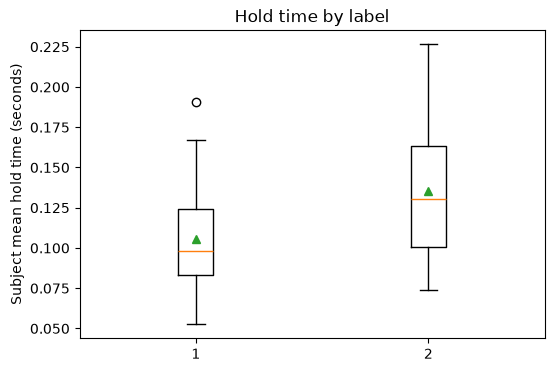

In [4]:
def boxplot(field, ylabel, title):
    values = [[r[field] for r in subject_rows if r['label_name']==label] for label in ['Control','PD']]
    plt.figure(figsize=(6,4)); plt.boxplot(values, label=['Control','PD'], showmeans=True)
    plt.ylabel(ylabel); plt.title(title); plt.show()

boxplot('mean_hold', 'Subject mean hold time (seconds)', 'Hold time by label')


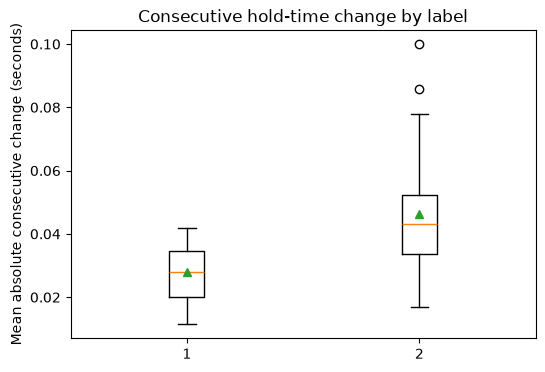

In [5]:
boxplot('mean_abs_consecutive_change', 'Mean absolute consecutive change (seconds)', 'Consecutive hold-time change by label')


## MACD feature comparison

MACD restricts consecutive changes to the upper hold-time corridor, defined per session by the 60th percentile through the maximum. This is the feature used in the replication model.

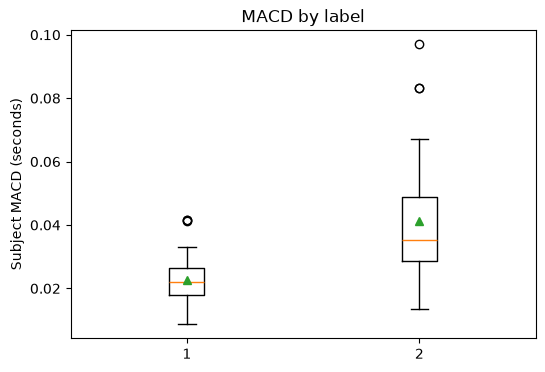

MIT-CS1PD Control n= 13 mean MACD= 0.024172 median= 0.022171
MIT-CS1PD PD n= 18 mean MACD= 0.046931 median= 0.039025
MIT-CS2PD Control n= 30 mean MACD= 0.022115 median= 0.021469
MIT-CS2PD PD n= 24 mean MACD= 0.036834 median= 0.033738


In [6]:
boxplot('macd', 'Subject MACD (seconds)', 'MACD by label')

for cohort in sorted({r['cohort'] for r in subject_rows}):
    for label, name in [(0,'Control'),(1,'PD')]:
        vals=[r['macd'] for r in subject_rows if r['cohort']==cohort and r['label']==label]
        print(cohort, name, 'n=',len(vals), 'mean MACD=',round(float(np.mean(vals)),6), 'median=',round(float(np.median(vals)),6))


## Interpretation and caution

If PD subjects show larger or more variable consecutive hold-time changes and the corridor-restricted MACD separates the labels, that supports using MACD as an interpretable candidate feature. These are descriptive associations, not proof of causality or clinical validity. The final AUC is computed by the reproducible evaluation script with subject-safe cross-cohort testing.